<a href="https://colab.research.google.com/github/MalezhykDaniil/ML/blob/main/%D0%A2%D0%B5%D1%81%D1%82%D0%BE%D0%B2%D0%B5_%D0%B7%D0%B0%D0%B2%D0%B4%D0%B0%D0%BD%D0%BD%D1%8F_ML_%D0%B4%D0%B6%D1%83%D0%BD%D1%96%D0%BE%D1%80_%D0%9C%D0%B0%D0%BB%D0%B5%D0%B6%D0%B8%D0%BA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Імпортування бібліотек

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, f1_score, precision_score, recall_score

Завантаження даних

In [2]:
import kagglehub
import os

path = kagglehub.dataset_download("barun2104/telecom-churn")
df = pd.read_csv(os.path.join(path, 'telecom_churn.csv'))
df.head()

100%|██████████| 45.5k/45.5k [00:00<00:00, 48.4MB/s]

Extracting files...


,Churn,AccountWeeks,ContractRenewal,DataPlan,DataUsage,CustServCalls,DayMins,DayCalls,MonthlyCharge,OverageFee,RoamMins
0,0,128,1,1,2.7,1,265.1,110,89.0,9.87,10.0
1,0,107,1,1,3.7,1,161.6,123,82.0,9.78,13.7
2,0,137,1,0,0.0,0,243.4,114,52.0,6.06,12.2
3,0,84,0,0,0.0,2,299.4,71,57.0,3.10,6.6
4,0,75,0,0,0.0,3,166.7,113,41.0,7.42,10.1


Опис даних

**Churn**: Бінарна цільова змінна, яка вказує, чи відмовився клієнт від послуг (1) чи залишився лояльним (0).   

**AccountWeeks**: Тривалість існування акаунта, виражена в тижнях.   

**ContractRenewal**: Індикатор того, чи поновлював клієнт свій контракт (0 або 1).   

**DataPlan**: Наявність у клієнта тарифного плану для передачі даних (0 — немає, 1 — є).   

**DataUsage**: Кількість використаних мобільних даних.   

**CustServCalls**: Кількість звернень абонента до служби підтримки клієнтів.   

**DayMins**: Загальна кількість хвилин дзвінків у денний час.   

**DayCalls**: Кількість здійснених дзвінків у денний час.   

**MonthlyCharge**: Середній розмір щомісячного рахунку клієнта.   

**OverageFee**: Сума додаткової комісії за перевищення лімітів тарифу.   

**RoamMins**: Кількість хвилин, витрачених у роумінгу.  

Первинний огляд датасету

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3333 entries, 0 to 3332
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Churn            3333 non-null   int64  
 1   AccountWeeks     3333 non-null   int64  
 2   ContractRenewal  3333 non-null   int64  
 3   DataPlan         3333 non-null   int64  
 4   DataUsage        3333 non-null   float64
 5   CustServCalls    3333 non-null   int64  
 6   DayMins          3333 non-null   float64
 7   DayCalls         3333 non-null   int64  
 8   MonthlyCharge    3333 non-null   float64
 9   OverageFee       3333 non-null   float64
 10  RoamMins         3333 non-null   float64
dtypes: float64(5), int64(6)
memory usage: 286.6 KB


In [4]:
df.isnull().sum()

,0
Churn,0
AccountWeeks,0
ContractRenewal,0
DataPlan,0
DataUsage,0
CustServCalls,0
DayMins,0
DayCalls,0
MonthlyCharge,0
OverageFee,0


In [5]:
df.duplicated().sum()

np.int64(0)

In [6]:
df.describe()

,Churn,AccountWeeks,ContractRenewal,DataPlan,DataUsage,CustServCalls,DayMins,DayCalls,MonthlyCharge,OverageFee,RoamMins
count,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000
mean,0.144914,101.064806,0.903090,0.276628,0.816475,1.562856,179.775098,100.435644,56.305161,10.051488,10.237294
std,0.352067,39.822106,0.295879,0.447398,1.272668,1.315491,54.467389,20.069084,16.426032,2.535712,2.791840
min,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,0.000000,0.000000
25%,0.000000,74.000000,1.000000,0.000000,0.000000,1.000000,143.700000,87.000000,45.000000,8.330000,8.500000
50%,0.000000,101.000000,1.000000,0.000000,0.000000,1.000000,179.400000,101.000000,53.500000,10.070000,10.300000
75%,0.000000,127.000000,1.000000,1.000000,1.780000,2.000000,216.400000,114.000000,66.200000,11.770000,12.100000
max,1.000000,243.000000,1.000000,1.000000,5.400000,9.000000,350.800000,165.000000,111.300000,18.190000,20.000000


In [7]:
df['Churn'].value_counts()

,count
Churn,
0,2850
1,483


Висновки щодо аналізу:

Дисбаланс класів (Imbalanced Classes):Лояльні клієнти (Churn = 0): 2850 (85.5%). Відтік клієнтів (Churn = 1): 483 (14.5%). Датасет незбалансований. Метрика Accuracy буде оманливою (модель, яка просто завжди передбачає 0, матиме точність 85.5%). При оцінці моделей потрібно орієнтуватися на F1-score, Recall, Precision або ROC-AUC.
Загальні характеристики клієнтів:Середній термін користування (AccountWeeks): 101 тиждень. Поновлення контракту (ContractRenewal): 90.3% клієнтів поновлюють контракт. Тарифні плани даних (DataPlan): Лише 27.7% мають підключений пакет даних. Звернення до підтримки (CustServCalls): У середньому 1.56 дзвінків, але є клієнти з високим значенням (до 9 дзвінків), що зазвичай є прямою ознакою незадоволеності послугами.

Візуальний опис даних

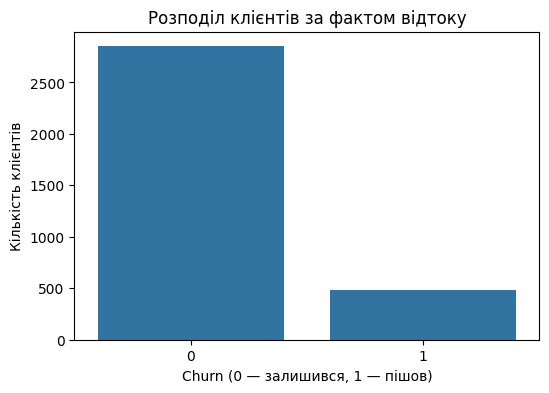

In [13]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Churn')
plt.title('Розподіл клієнтів за фактом відтоку')
plt.xlabel('Churn (0 — залишився, 1 — пішов)')
plt.ylabel('Кількість клієнтів')
plt.show()

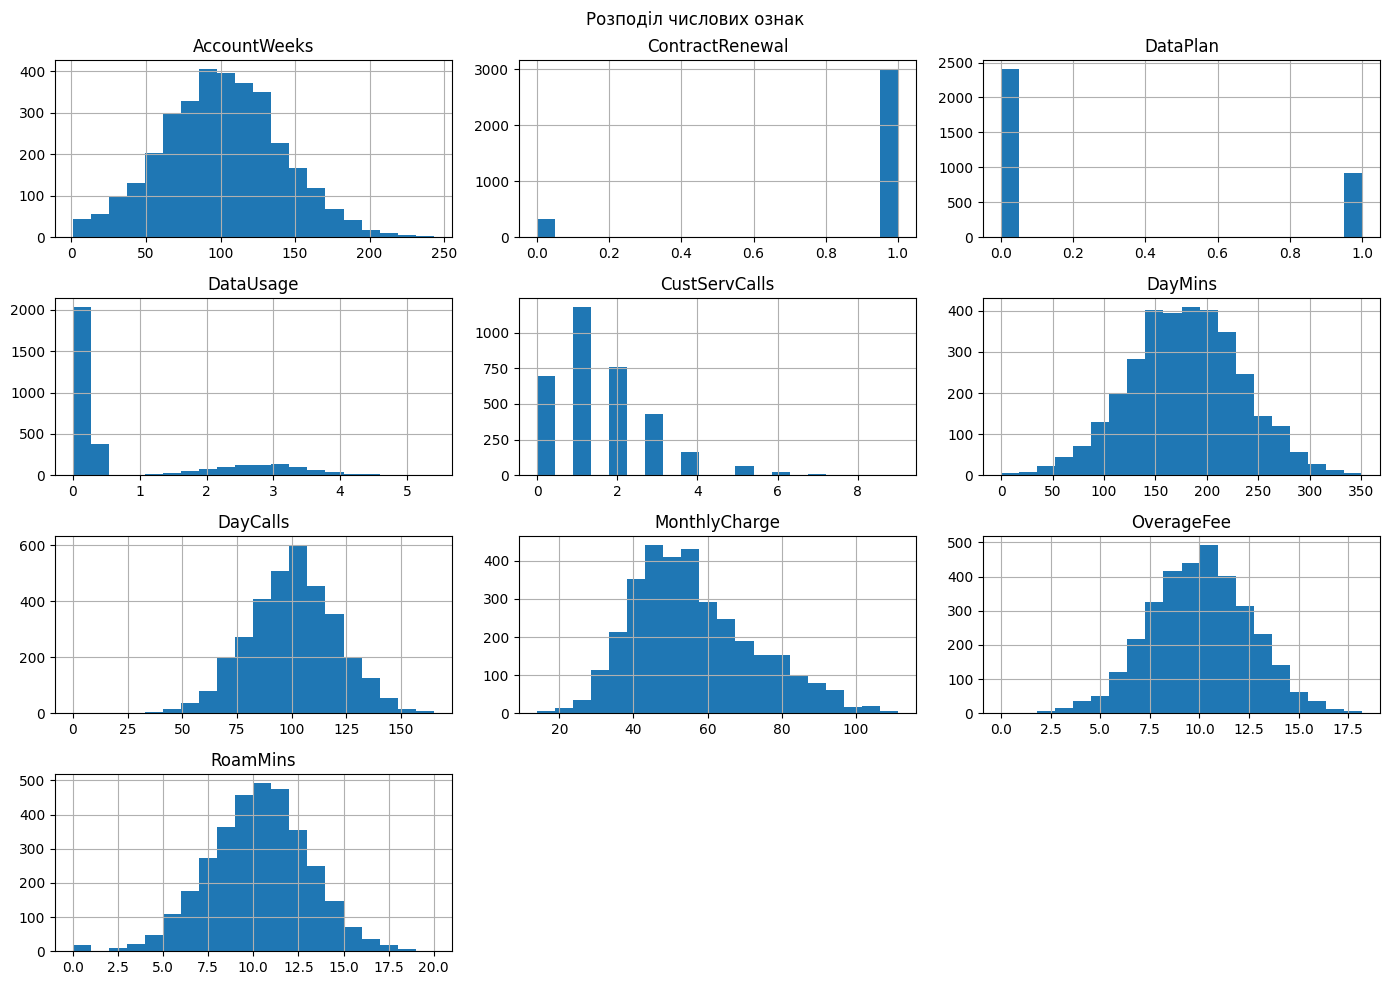

In [14]:
numeric_columns = df.select_dtypes(include=np.number).columns.tolist()
feature_columns = [c for c in numeric_columns if c != 'Churn']

df[feature_columns].hist(figsize=(14, 10), bins=20)
plt.suptitle('Розподіл числових ознак')
plt.tight_layout()
plt.show()

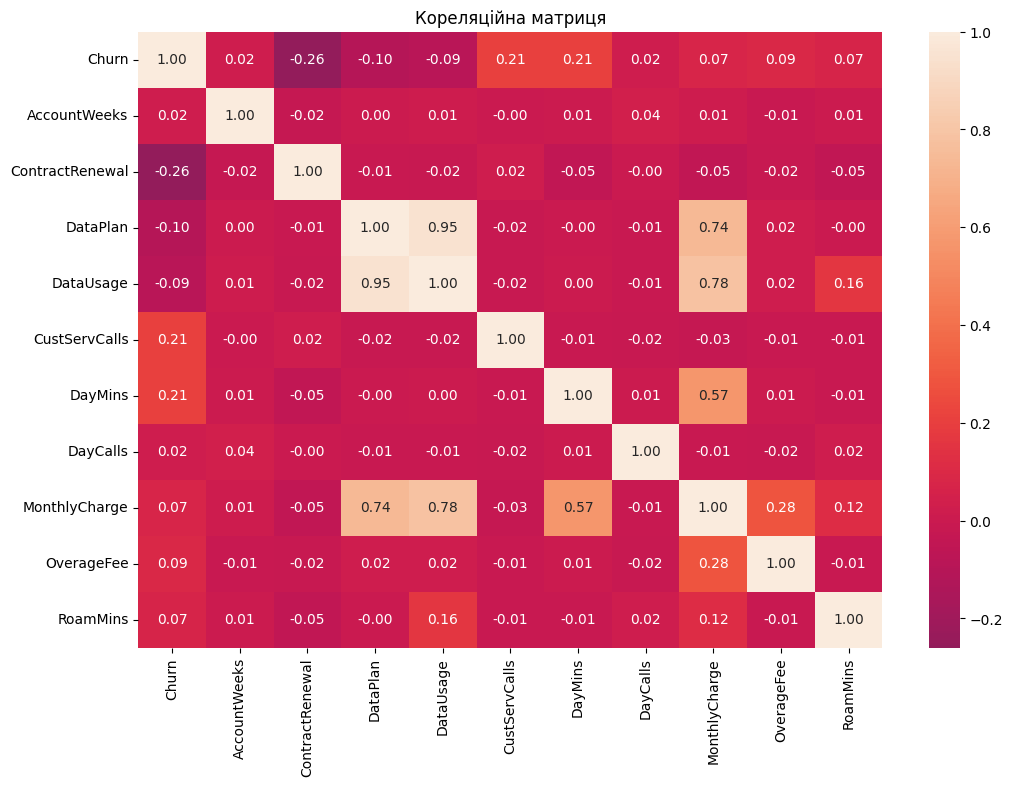

In [10]:
plt.figure(figsize=(12, 8))
sns.heatmap(df[numeric_columns].corr(), annot=True, fmt='.2f', cmap='rocket', center=0)
plt.title('Кореляційна матриця')
plt.show()

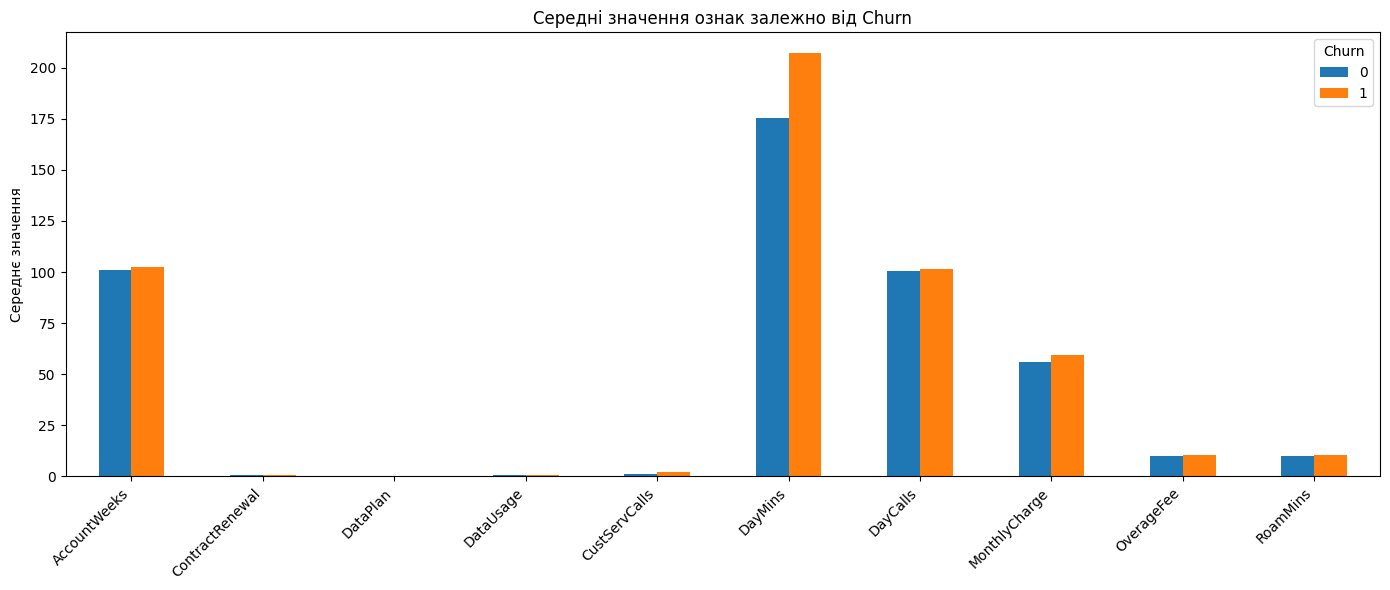

In [11]:
churn_means = df.groupby('Churn')[feature_columns].mean().T
churn_means.plot(kind='bar', figsize=(14, 6))
plt.title('Середні значення ознак залежно від Churn')
plt.ylabel('Середнє значення')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

Підготовка даних

In [15]:
target = 'Churn'
X = df.drop(columns=[target]).copy()
y = df[target].copy()

id_like = [c for c in X.columns if c.lower() in ('id', 'customerid', 'customer_id')]
if id_like:
    X = X.drop(columns=id_like)

print('Кількість записів:', len(df))
print('Кількість ознак:', X.shape[1])
print('Розподіл класів:')
print(y.value_counts())
print('\nВідсотковий розподіл:')
print((y.value_counts(normalize=True) * 100).round(2))
print('\nТипи ознак:')
print(X.dtypes)

Кількість записів: 3333
Кількість ознак: 10
Розподіл класів:
Churn
0    2850
1     483
Name: count, dtype: int64

Відсотковий розподіл:
Churn
0    85.51
1    14.49
Name: proportion, dtype: float64

Типи ознак:
AccountWeeks         int64
ContractRenewal      int64
DataPlan             int64
DataUsage          float64
CustServCalls        int64
DayMins            float64
DayCalls             int64
MonthlyCharge      float64
OverageFee         float64
RoamMins           float64
dtype: object


In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print('Train:', X_train.shape, 'Test:', X_test.shape)
print('Train target proportions:')
print(y_train.value_counts(normalize=True).round(3))


Train: (2666, 10) Test: (667, 10)
Train target proportions:
Churn
0    0.855
1    0.145
Name: proportion, dtype: float64


Побудова моделей

In [17]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import roc_auc_score
from sklearn.base import clone

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

models = {
    'Logistic Regression': LogisticRegression(max_iter=2000, class_weight='balanced'),
    'Decision Tree': DecisionTreeClassifier(random_state=42, class_weight='balanced'),
    'Random Forest': RandomForestClassifier(random_state=42, class_weight='balanced'),
    'SVM': SVC(probability=True, random_state=42, class_weight='balanced'),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42)
}

results = []
trained_models = {}

for model_name, model in models.items():
    pipeline = Pipeline(steps=[
        ('preprocessor', clone(preprocessor)),
        ('model', model)
    ])
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]
    results.append({
        'Model': model_name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1': f1_score(y_test, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, y_prob)
    })
    trained_models[model_name] = pipeline

results_df = pd.DataFrame(results).sort_values('F1', ascending=False)
results_df.round(4)


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
2,Random Forest,0.9280,0.8451,0.6186,0.7143,0.8546
4,Gradient Boosting,0.9205,0.7619,0.6598,0.7072,0.8612
1,Decision Tree,0.8831,0.5905,0.6392,0.6139,0.7819
3,SVM,0.8441,0.4774,0.7629,0.5873,0.8684
0,Logistic Regression,0.7601,0.3478,0.7423,0.4737,0.8095


Порівняння результатів

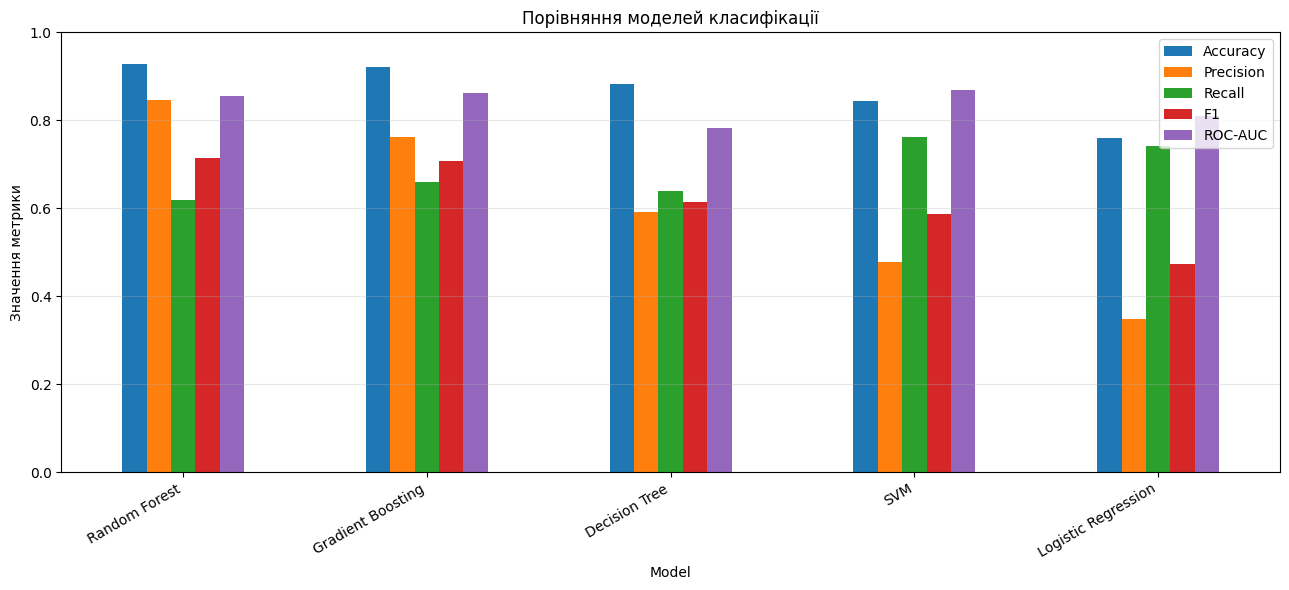

In [18]:
results_df.set_index('Model')[['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC']].plot(
    kind='bar', figsize=(13, 6)
)
plt.title('Порівняння моделей класифікації')
plt.ylabel('Значення метрики')
plt.ylim(0, 1)
plt.xticks(rotation=30, ha='right')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


Підбір гіепрпараметрів

In [19]:
rf_pipeline = Pipeline(steps=[
    ('preprocessor', clone(preprocessor)),
    ('model', RandomForestClassifier(random_state=42, class_weight='balanced'))
])

param_grid = {
    'model__n_estimators': [100, 200],
    'model__max_depth': [None, 8, 15],
    'model__min_samples_split': [2, 5],
    'model__min_samples_leaf': [1, 2]
}

grid_search = GridSearchCV(
    rf_pipeline,
    param_grid=param_grid,
    scoring='f1',
    cv=5,
    n_jobs=-1,
    verbose=1
)
grid_search.fit(X_train, y_train)

print('Найкращі параметри:', grid_search.best_params_)
print('Найкращий F1 на CV:', round(grid_search.best_score_, 4))


Fitting 5 folds for each of 24 candidates, totalling 120 fits
Найкращі параметри: {'model__max_depth': 15, 'model__min_samples_leaf': 2, 'model__min_samples_split': 2, 'model__n_estimators': 200}
Найкращий F1 на CV: 0.7694


Вибір найкращої моделі

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Random Forest,0.9280,0.8451,0.6186,0.7143,0.8546
1,Gradient Boosting,0.9205,0.7619,0.6598,0.7072,0.8612
5,Tuned Random Forest,0.9160,0.7412,0.6495,0.6923,0.8527
2,Decision Tree,0.8831,0.5905,0.6392,0.6139,0.7819
3,SVM,0.8441,0.4774,0.7629,0.5873,0.8684
4,Logistic Regression,0.7601,0.3478,0.7423,0.4737,0.8095


Обрана модель: Random Forest

Classification report:
              precision    recall  f1-score   support

           0       0.94      0.98      0.96       570
           1       0.85      0.62      0.71        97

    accuracy                           0.93       667
   macro avg       0.89      0.80      0.84       667
weighted avg       0.92      0.93      0.92       667



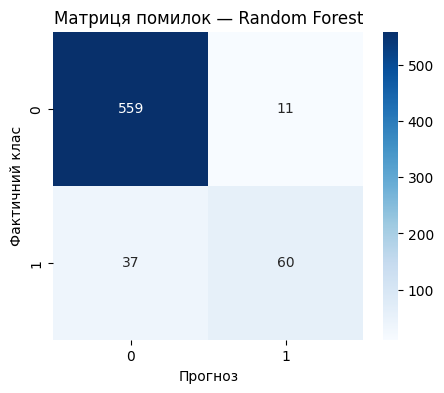

In [20]:
best_tuned_model = grid_search.best_estimator_
tuned_pred = best_tuned_model.predict(X_test)
tuned_prob = best_tuned_model.predict_proba(X_test)[:, 1]

tuned_metrics = {
    'Model': 'Tuned Random Forest',
    'Accuracy': accuracy_score(y_test, tuned_pred),
    'Precision': precision_score(y_test, tuned_pred, zero_division=0),
    'Recall': recall_score(y_test, tuned_pred, zero_division=0),
    'F1': f1_score(y_test, tuned_pred, zero_division=0),
    'ROC-AUC': roc_auc_score(y_test, tuned_prob)
}

final_results = pd.concat([
    results_df,
    pd.DataFrame([tuned_metrics])
], ignore_index=True).sort_values('F1', ascending=False)

display(final_results.round(4))

best_model_name = final_results.iloc[0]['Model']
if best_model_name == 'Tuned Random Forest':
    best_model = best_tuned_model
else:
    best_model = trained_models[best_model_name]

best_predictions = best_model.predict(X_test)
best_probabilities = best_model.predict_proba(X_test)[:, 1]

print('Обрана модель:', best_model_name)
print('\nClassification report:')
print(classification_report(y_test, best_predictions, zero_division=0))

cm = confusion_matrix(y_test, best_predictions)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title(f'Матриця помилок — {best_model_name}')
plt.xlabel('Прогноз')
plt.ylabel('Фактичний клас')
plt.show()


Прогноз

In [21]:
new_customer = {}
for col in X.columns:
    if pd.api.types.is_numeric_dtype(X[col]):
        new_customer[col] = X_train[col].median()
    else:
        new_customer[col] = X_train[col].mode(dropna=True).iloc[0]

customer_df = pd.DataFrame([new_customer], columns=X.columns)
prediction = int(best_model.predict(customer_df)[0])
churn_probability = float(best_model.predict_proba(customer_df)[0, 1])

print('Вхідні дані клієнта:')
display(customer_df)
print('Прогноз:', 'Клієнт піде (відтік)' if prediction == 1 else 'Клієнт залишиться')
print(f'Ймовірність відтоку: {churn_probability:.2%}')


Вхідні дані клієнта:


,AccountWeeks,ContractRenewal,DataPlan,DataUsage,CustServCalls,DayMins,DayCalls,MonthlyCharge,OverageFee,RoamMins
0,101.0,1.0,0.0,0.0,1.0,179.3,101.0,53.5,10.06,10.3


Прогноз: Клієнт залишиться
Ймовірність відтоку: 2.00%


Висновок:

У роботі завантажено та проаналізовано датасет Telecom Churn: перевірено структуру даних, пропуски, дублікати, розподіл класів і статистичні характеристики. Дані розділено на тренувальну та тестову вибірки зі збереженням співвідношення класів, а для числових і категоріальних ознак виконано обробку пропусків, масштабування та кодування. Для прогнозування відтоку клієнтів реалізовано й порівняно Logistic Regression, Decision Tree, Random Forest, SVM і Gradient Boosting за Accuracy, Precision, Recall, F1-score та ROC-AUC. Для Random Forest підібрано гіперпараметри за допомогою GridSearchCV, після чого найкращу модель обрано за результатами порівняння і перевірено на тестовій вибірці через classification report і матрицю помилок.